## 1. Setup and data

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter, MaxNLocator
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
BURGUNDY, GOLD, BLUE = "#7b1e3b", "#c28e36", "#377a96"
USD = StrMethodFormatter("${x:,.0f}")

DATA_FILE = Path("datasets/winemag-data-130k-v2.csv")
raw = pd.read_csv(DATA_FILE)
raw = raw.loc[:, ~raw.columns.str.startswith("Unnamed:")]
print(f"Loaded {len(raw):,} rows from {DATA_FILE}")
raw[["title", "price", "country", "variety"]].head()

Loaded 129,971 rows from datasets/winemag-data-130k-v2.csv


,title,price,country,variety
0,Nicosia 2013 Vulkà Bianco (Etna),NaN,Italy,White Blend
1,Quinta dos Avidagos 2011 Avidagos Red (Douro),15.0,Portugal,Portuguese Red
2,Rainstorm 2013 Pinot Gris (Willamette Valley),14.0,US,Pinot Gris
3,St. Julian 2013 Reserve Late Harvest Riesling ...,13.0,US,Riesling
4,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,65.0,US,Pinot Noir


## 2. Cleaning and vintage checks
Remove repeated `(title, description)` pairs, keeping the first record to match Angel’s notebook. These are review-level observations, not necessarily unique wine products.

Extract four-digit candidate years from titles after removing the exact winery prefix (which can itself contain a year). Titles marked `NV` are treated as non-vintage; titles containing multiple remaining candidate years are left unresolved rather than choosing an arbitrary year. This is a conservative adjustment to the other notebooks’ first-year extraction. A missing extracted year can mean non-vintage, an ambiguous title, or no recognizable year. Older years may be real special releases, so they are inspected rather than automatically treated as mistakes.

In [2]:
df = raw.drop_duplicates(subset=["title", "description"]).copy()
duplicates_removed = len(raw) - len(df)
original_price = df["price"].copy()
df["price"] = pd.to_numeric(df["price"], errors="coerce")
invalid_price = df["price"].notna() & (~np.isfinite(df["price"]) | df["price"].le(0))
df.loc[invalid_price, "price"] = np.nan

YEAR_PATTERN = r"\b(?:19|20)\d{2}\b"
def vintage_candidates(title, winery):
    if pd.isna(title):
        return []
    text = str(title)
    if pd.notna(winery) and text.startswith(str(winery) + " "):
        text = text[len(str(winery)):].strip()
    if re.search(r"\bNV\b", text, flags=re.IGNORECASE):
        return []
    return re.findall(YEAR_PATTERN, text)

candidates = pd.Series(
    [vintage_candidates(t, w) for t, w in zip(df["title"], df["winery"])],
    index=df.index,
)
df["vintage"] = pd.Series(
    [int(years[0]) if len(years) == 1 else pd.NA for years in candidates],
    index=df.index, dtype="Int64",
)
first_year = pd.to_numeric(df["title"].str.extract(f"({YEAR_PATTERN})", expand=False), errors="coerce").astype("Int64")
changed_extraction = first_year.fillna(-1).ne(df["vintage"].fillna(-1))
print(f"Repeated review pairs removed: {duplicates_removed:,}")
print(f"Rows after deduplication: {len(df):,}")
print(f"Invalid/nonpositive prices set to missing: {invalid_price.sum():,}")
print(f"Titles with multiple remaining year candidates: {candidates.str.len().gt(1).sum():,}")
print(f"Vintage assignments changed from first-year extraction: {changed_extraction.sum():,}")
df.loc[changed_extraction, ["title", "winery", "vintage"]].head(12)

Repeated review pairs removed: 9,983
Rows after deduplication: 119,988
Invalid/nonpositive prices set to missing: 0
Titles with multiple remaining year candidates: 69
Vintage assignments changed from first-year extraction: 87


,title,winery,vintage
1512,Pascal Aufranc 2011 Vignes de 1939 (Chénas),Pascal Aufranc,<NA>
3044,Pascal Aufranc 2015 En Rémont Vignes de 1939 ...,Pascal Aufranc,<NA>
7986,Guidi 1929 2012 Aurea Riserva (Vernaccia di S...,Guidi 1929,2012
8407,Kirsten 2013 1904 Spätlese Riesling (Mosel),Kirsten,<NA>
9728,1912 Winemakers 2011 Vinhas Velhas Branco Whit...,1912 Winemakers,2011
9808,Casella 2007 1919 Shiraz (Wrattonbully),Casella,<NA>
10494,Domaine de la Tour Boisée 2006 Plantation 1905...,Domaine de la Tour Boisée,<NA>
10735,Arndorfer 2013 Von Den Terrassen 1979 Roter Ve...,Arndorfer,<NA>
12110,Owen Roe 2014 1973 Block Red Willow Vineyard C...,Owen Roe,<NA>
13432,Producteurs Plaimont 2007 Cuvée 1907 Tannat (M...,Producteurs Plaimont,<NA>


In [3]:
coverage = pd.DataFrame({
    "check": ["All deduplicated reviews", "Missing/invalid price", "No resolved vintage", "Missing both", "Usable price and vintage"],
    "reviews": [len(df), df["price"].isna().sum(), df["vintage"].isna().sum(),
                (df["price"].isna() & df["vintage"].isna()).sum(),
                (df["price"].notna() & df["vintage"].notna()).sum()],
})
coverage["percent_of_deduplicated"] = 100 * coverage["reviews"] / len(df)
coverage.round(2)

,check,reviews,percent_of_deduplicated
0,All deduplicated reviews,119988,100.00
1,Missing/invalid price,8395,7.00
2,No resolved vintage,4359,3.63
3,Missing both,454,0.38
4,Usable price and vintage,107688,89.75


In [4]:
print("Missing-price and unresolved-vintage counts overlap; do not add them together.")
price_df = df.dropna(subset=["price", "vintage"]).copy()
price_df["price"].describe(percentiles=[.25, .5, .75, .9, .95, .99]).to_frame("recorded_price_USD").round(2)

Missing-price and unresolved-vintage counts overlap; do not add them together.


,recorded_price_USD
count,107688.00
mean,35.76
std,42.32
min,4.00
25%,17.00
50%,25.00
75%,42.00
90%,65.00
95%,85.00
99%,160.00


In [5]:
print("Oldest extracted vintages (manual inspection):")
price_df.nsmallest(10, "vintage")[["title", "vintage", "price"]]

Oldest extracted vintages (manual inspection):


,title,vintage,price
107854,Adega Viuva Gomes 1934 Reserva Velho Red (Cola...,1934,495.0
41441,Kopke 1935 Colheita White (Port),1935,980.0
90583,Kopke 1941 Colheita Tawny (Port),1941,770.0
117205,Gérard Bertrand 1945 Legend Vintage Red (Rives...,1945,350.0
51898,"Bodegas Toro Albala, SL 1947 Don PX Reserva Es...",1947,258.0
82827,Messias 1952 Porto Envelhecido em Casco Colhei...,1952,499.0
87131,Burmester 1952 Colheita Tawny (Port),1952,415.0
78299,Kopke 1957 Colheita Tawny (Port),1957,375.0
78312,Cálem 1961 Colheita Tawny (Port),1961,320.0
52636,Dow's 1963 Vintage (Port),1963,467.0


## 3. Which years have enough price data?
Keep a full by-vintage table for inspection. Focus charts on **2004–2017**, matching Angel’s initial exploration, and retain years with at least **100 priced reviews** for comparisons. This is a descriptive readability rule, not a statistical guarantee. Show all years in that window in the coverage chart so small batches remain visible. Missing prices are not imputed.

In [6]:
START_YEAR, END_YEAR = 2004, 2017
MIN_PRICED_REVIEWS = 100

yearly = df.dropna(subset=["vintage"]).groupby("vintage").agg(
    n_reviews=("title", "size"), n_priced=("price", "count"),
    mean_price=("price", "mean"), median_price=("price", "median"),
    q25=("price", lambda s: s.quantile(.25)), q75=("price", lambda s: s.quantile(.75)),
    p90=("price", lambda s: s.quantile(.90)), max_price=("price", "max"),
)
yearly["missing_price_pct"] = 100 * (1 - yearly["n_priced"] / yearly["n_reviews"])
yearly["used_in_focus"] = yearly.index.to_series().between(START_YEAR, END_YEAR) & yearly["n_priced"].ge(MIN_PRICED_REVIEWS)
yearly.round(2)

,n_reviews,n_priced,mean_price,median_price,q25,q75,p90,max_price,missing_price_pct,used_in_focus
vintage,,,,,,,,,,
1934,1,1,495.00,495.0,495.00,495.00,495.0,495.0,0.00,False
1935,1,1,980.00,980.0,980.00,980.00,980.0,980.0,0.00,False
1941,1,1,770.00,770.0,770.00,770.00,770.0,770.0,0.00,False
1945,1,1,350.00,350.0,350.00,350.00,350.0,350.0,0.00,False
1947,1,1,258.00,258.0,258.00,258.00,258.0,258.0,0.00,False
1952,2,2,457.00,457.0,436.00,478.00,490.6,499.0,0.00,False
1957,1,1,375.00,375.0,375.00,375.00,375.0,375.0,0.00,False
1961,1,1,320.00,320.0,320.00,320.00,320.0,320.0,0.00,False
1963,3,3,552.33,467.0,433.50,628.50,725.4,790.0,0.00,False


In [7]:
focus_years = yearly.index[yearly["used_in_focus"]].astype(int).tolist()
focus = price_df[price_df["vintage"].isin(focus_years)].copy()
focus["vintage"] = focus["vintage"].astype(int)
trend = yearly.loc[focus_years].copy()
print(f"Focus years: {focus_years}")
print(f"Focus contains {len(focus):,} priced reviews ({len(focus) / len(price_df):.1%} of usable price/vintage rows).")
yearly.loc[yearly.index.to_series().between(START_YEAR, END_YEAR) & ~yearly["used_in_focus"], ["n_reviews", "n_priced", "missing_price_pct"]].rename_axis("excluded_focus_year")

Focus years: [2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]
Focus contains 103,824 priced reviews (96.4% of usable price/vintage rows).


,n_reviews,n_priced,missing_price_pct
excluded_focus_year,,,
2017,11,11,0.0


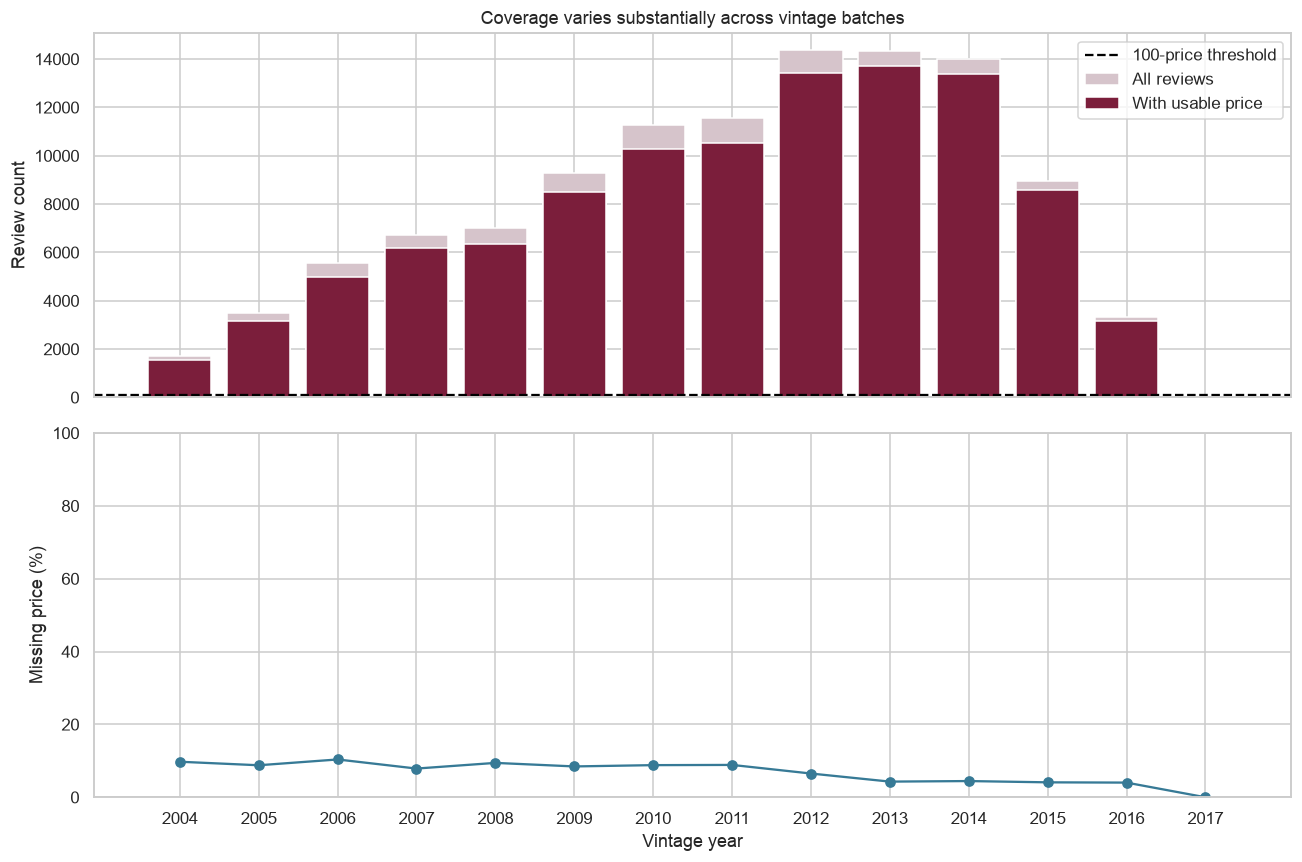

In [8]:
window = yearly.reindex(range(START_YEAR, END_YEAR + 1))
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].bar(window.index, window["n_reviews"], color="#d6c4cb", label="All reviews")
axes[0].bar(window.index, window["n_priced"], color=BURGUNDY, label="With usable price")
axes[0].axhline(MIN_PRICED_REVIEWS, color="black", linestyle="--", label=f"{MIN_PRICED_REVIEWS}-price threshold")
axes[0].set(title="Coverage varies substantially across vintage batches", ylabel="Review count")
axes[0].legend()
axes[1].plot(window.index, window["missing_price_pct"], marker="o", color=BLUE)
axes[1].set(xlabel="Vintage year", ylabel="Missing price (%)", ylim=(0, 100))
axes[1].set_xticks(window.index)
plt.tight_layout()
plt.show()

**How to read this:** Yearly comparisons use different numbers of reviews. A small latest-vintage batch should not carry the same evidential weight as a large middle-vintage batch. Missing prices may also change which wines are represented; this chart does not establish that missingness is random.

## 4. Overall price distribution
Wine prices have a long right tail. The first histogram shows prices up to the focus sample’s 99th percentile for readability, with the omitted count printed below. The second includes **all** focus prices using logarithmically spaced bins and a log price axis. Summary tables and subsequent calculations retain expensive wines.

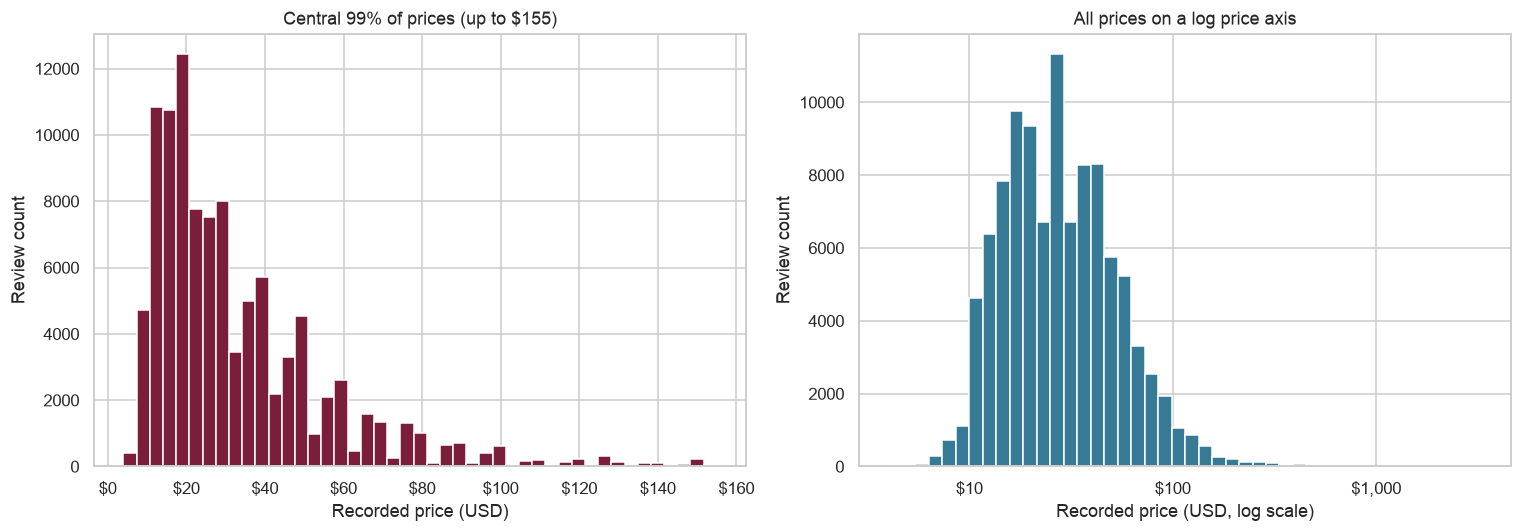

Prices above $155 omitted from the left panel only: 1,016
Focus mean: $35.65; median: $25.00; maximum: $3,300


In [9]:
cap = focus["price"].quantile(.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(focus.loc[focus["price"].le(cap), "price"], bins=45, color=BURGUNDY, edgecolor="white")
axes[0].set(title=f"Central 99% of prices (up to ${cap:,.0f})", xlabel="Recorded price (USD)", ylabel="Review count")
axes[0].xaxis.set_major_formatter(USD)
bins = np.geomspace(focus["price"].min(), focus["price"].max(), 45)
axes[1].hist(focus["price"], bins=bins, color=BLUE, edgecolor="white")
axes[1].set_xscale("log")
axes[1].set(title="All prices on a log price axis", xlabel="Recorded price (USD, log scale)", ylabel="Review count")
axes[1].xaxis.set_major_formatter(USD)
plt.tight_layout()
plt.show()
print(f"Prices above ${cap:,.0f} omitted from the left panel only: {focus['price'].gt(cap).sum():,}")
print(f"Focus mean: ${focus['price'].mean():.2f}; median: ${focus['price'].median():.2f}; maximum: ${focus['price'].max():,.0f}")

## 5. Typical price and spread by vintage
Compare the mean with the median, and show the 25th–75th percentile band (the middle half of observed prices). This band describes variation between reviews, **not** uncertainty around the median.

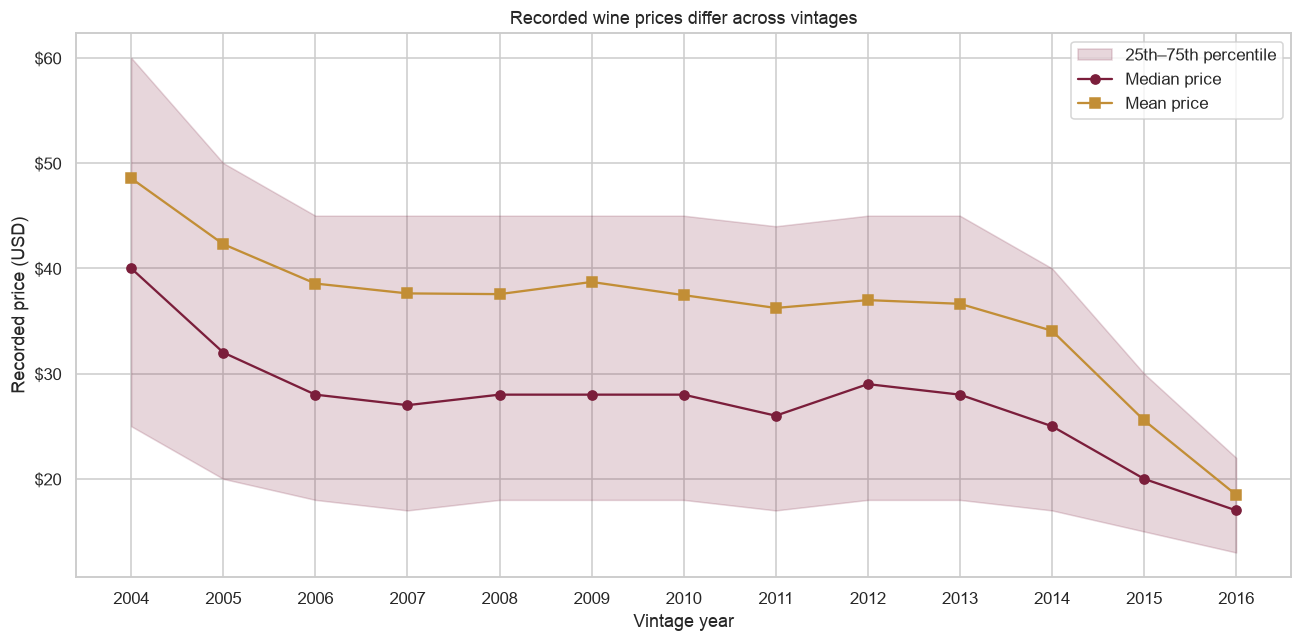

,n_priced,mean_price,median_price,q25,q75,p90
vintage,,,,,,
2004,1546,48.55,40.0,25.0,60.0,90.0
2005,3178,42.30,32.0,20.0,50.0,75.0
2006,4985,38.56,28.0,18.0,45.0,71.6
2007,6198,37.62,27.0,17.0,45.0,70.0
2008,6356,37.55,28.0,18.0,45.0,70.0
2009,8492,38.71,28.0,18.0,45.0,70.0
2010,10291,37.45,28.0,18.0,45.0,70.0
2011,10522,36.24,26.0,17.0,44.0,66.0
2012,13420,36.98,29.0,18.0,45.0,68.0


In [10]:
x = trend.index.to_numpy(dtype=int)
fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(x, trend["q25"].to_numpy(), trend["q75"].to_numpy(), alpha=.18, color=BURGUNDY, label="25th–75th percentile")
ax.plot(x, trend["median_price"], marker="o", color=BURGUNDY, label="Median price")
ax.plot(x, trend["mean_price"], marker="s", color=GOLD, label="Mean price")
ax.set(title="Recorded wine prices differ across vintages", xlabel="Vintage year", ylabel="Recorded price (USD)")
ax.set_xticks(x)
ax.yaxis.set_major_formatter(USD)
ax.legend()
plt.tight_layout()
plt.show()
trend[["n_priced", "mean_price", "median_price", "q25", "q75", "p90"]].round(2)

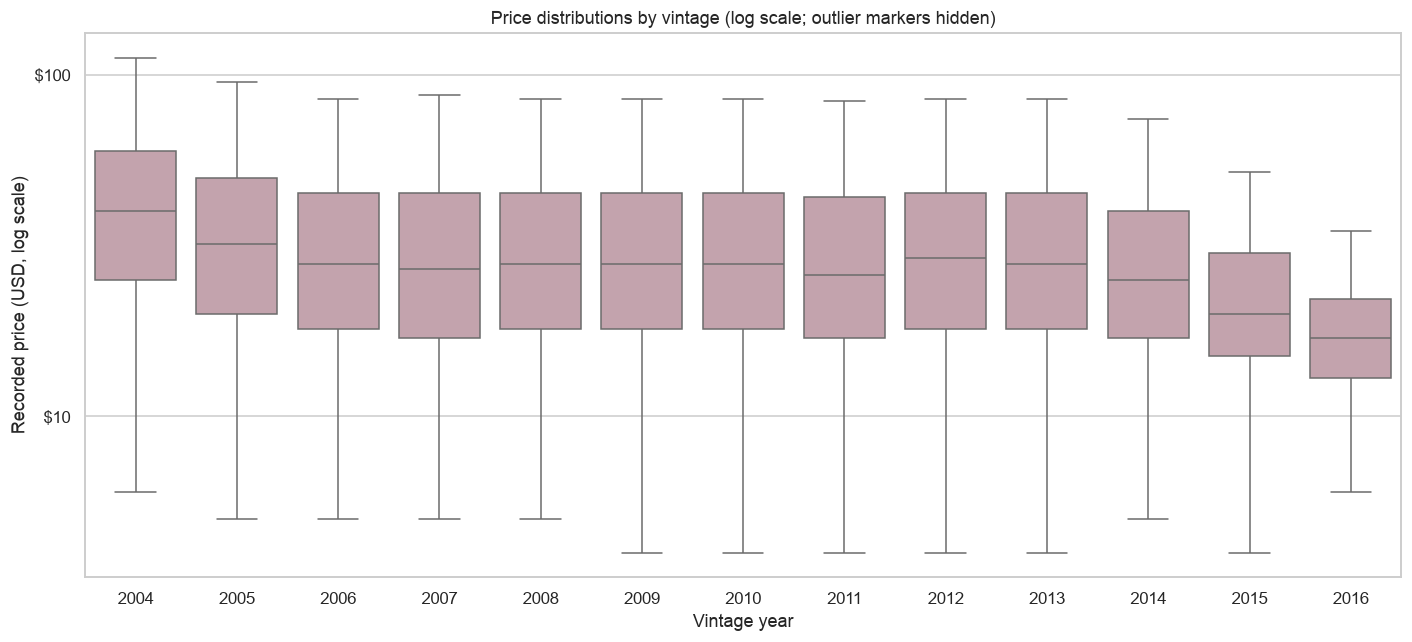

In [11]:
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=focus, x="vintage", y="price", order=focus_years, color="#c99dab", showfliers=False, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(USD)
ax.set(title="Price distributions by vintage (log scale; outlier markers hidden)", xlabel="Vintage year", ylabel="Recorded price (USD, log scale)")
plt.tight_layout()
plt.show()

Boxes show medians and the middle 50% of prices; whiskers extend to the most extreme observations within 1.5 interquartile ranges. Outlier markers are hidden to keep the boxes readable, but observations remain in the calculations. Log spacing emphasizes proportional differences, so equal vertical distances do not represent equal dollar differences.

## 6. Does the mix of price ranges change?
These fixed exploratory brackets describe the distribution; they are not learned classes or a modeling decision. The intervals are $0–<15, $15–<30, $30–<50, $50–<100, and $100+. All percentages use only reviews with usable prices and vintages.

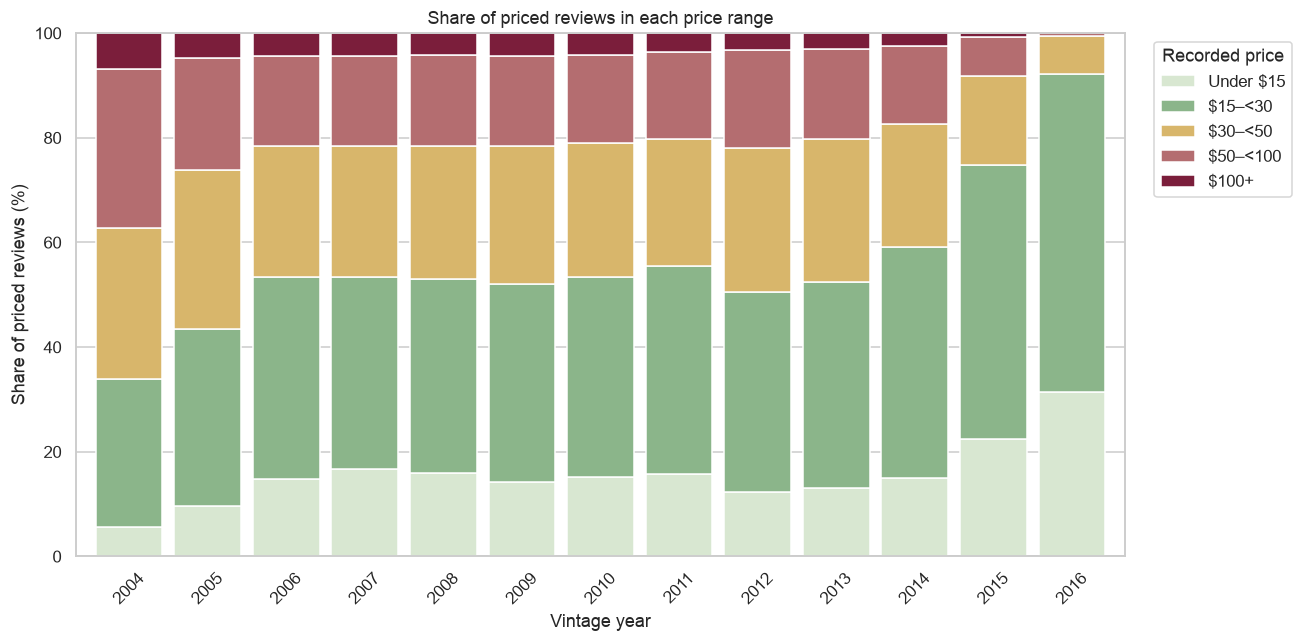

price_band,Under $15,$15–<30,$30–<50,$50–<100,$100+
vintage,,,,,
2004,5.6,28.3,28.8,30.4,6.9
2005,9.6,33.8,30.4,21.5,4.7
2006,14.7,38.7,24.9,17.2,4.4
2007,16.7,36.7,25.1,17.2,4.4
2008,15.9,37.1,25.3,17.4,4.2
2009,14.2,37.9,26.2,17.3,4.3
2010,15.2,38.1,25.6,16.9,4.1
2011,15.7,39.8,24.3,16.6,3.6
2012,12.3,38.2,27.6,18.7,3.2


In [12]:
PRICE_BINS = [0, 15, 30, 50, 100, np.inf]
PRICE_LABELS = ["Under $15", "$15–<30", "$30–<50", "$50–<100", "$100+"]
focus["price_band"] = pd.cut(focus["price"], bins=PRICE_BINS, labels=PRICE_LABELS, right=False)
band_share = pd.crosstab(focus["vintage"], focus["price_band"], normalize="index").reindex(columns=PRICE_LABELS, fill_value=0) * 100
ax = band_share.plot(kind="bar", stacked=True, figsize=(12, 6), color=["#d8e7d1", "#8bb58a", "#d8b66b", "#b46d70", BURGUNDY], width=.85)
ax.set(title="Share of priced reviews in each price range", xlabel="Vintage year", ylabel="Share of priced reviews (%)", ylim=(0, 100))
ax.legend(title="Recorded price", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
band_share.round(1)

## 7. Could country composition help explain the overall pattern?
Compare medians within the five most reviewed countries in the focus sample, and inspect those countries’ changing shares of priced reviews. Require at least 100 priced reviews in each country/year cell; missing cells break lines rather than bridging sparse years. These are descriptive comparisons, not adjustments for variety, winery, wine style, or bottle size.

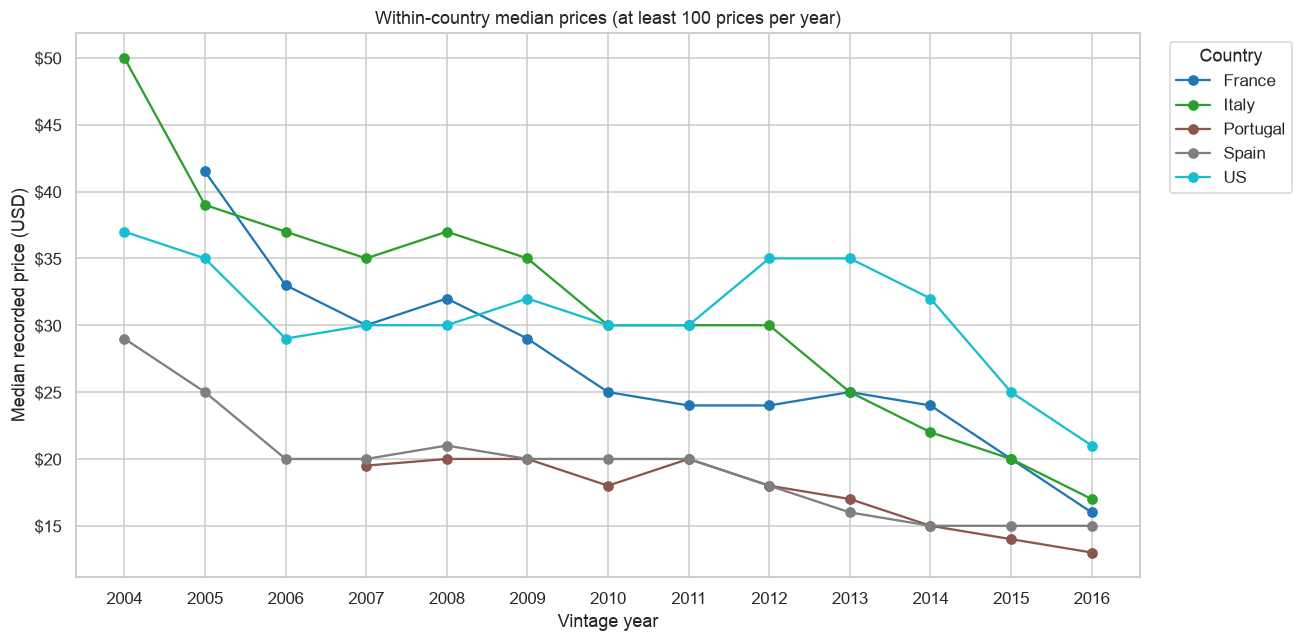

Counts behind the country/year comparisons (including cells excluded from the lines):


country,France,Italy,Portugal,Spain,US
vintage,,,,,
2004,92,473,55,179,527
2005,314,516,82,243,1537
2006,409,844,72,299,2376
2007,524,1181,124,347,2772
2008,591,993,206,408,2928
2009,978,1252,280,535,3971
2010,1312,1651,304,555,4792
2011,1334,1945,410,645,4381
2012,1478,1940,495,556,6984


In [13]:
TOP_COUNTRY_COUNT = 5
MIN_COUNTRY_YEAR = 100
top_countries = focus["country"].value_counts().head(TOP_COUNTRY_COUNT).index.tolist()
country_year = focus[focus["country"].isin(top_countries)].groupby(["vintage", "country"]).agg(
    n_priced=("price", "size"), median_price=("price", "median"),
).reset_index()
country_medians = country_year.pivot(index="vintage", columns="country", values="median_price").reindex(focus_years)
country_counts = country_year.pivot(index="vintage", columns="country", values="n_priced").reindex(focus_years).fillna(0).astype(int)
country_medians = country_medians.where(country_counts.ge(MIN_COUNTRY_YEAR))
ax = country_medians.plot(marker="o", figsize=(12, 6), colormap="tab10")
ax.set(title=f"Within-country median prices (at least {MIN_COUNTRY_YEAR} prices per year)", xlabel="Vintage year", ylabel="Median recorded price (USD)")
ax.set_xticks(focus_years)
ax.yaxis.set_major_formatter(USD)
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
print("Counts behind the country/year comparisons (including cells excluded from the lines):")
country_counts

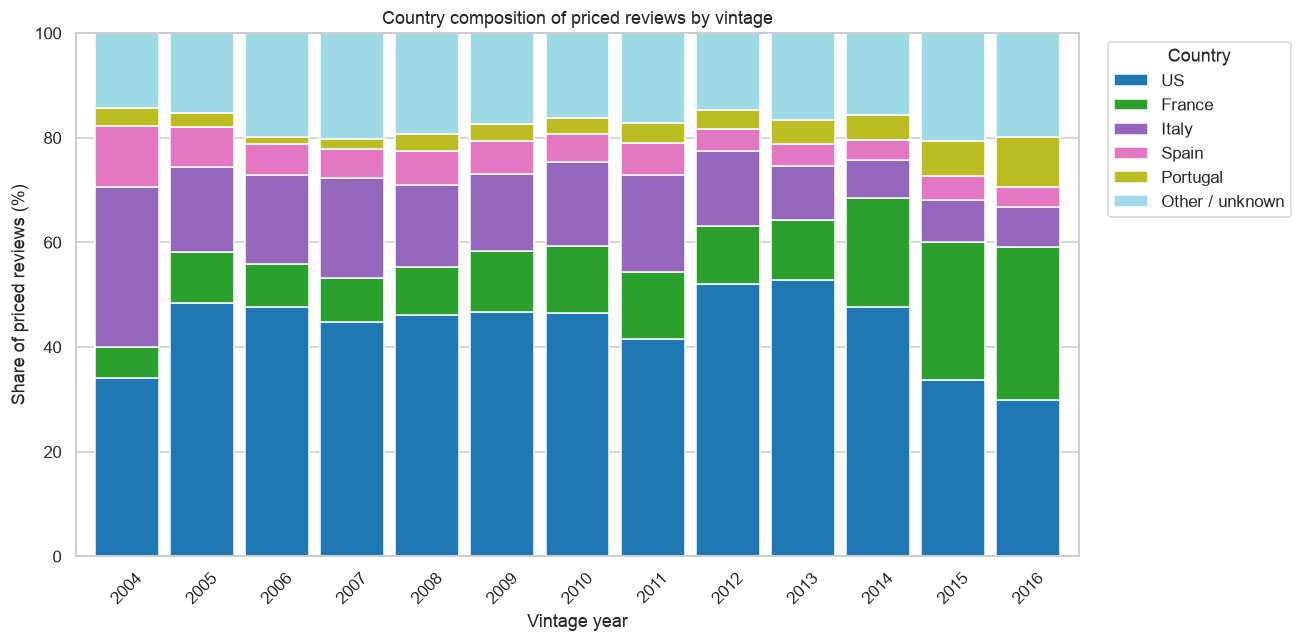

In [14]:
country_mix = focus.assign(country_group=focus["country"].where(focus["country"].isin(top_countries), "Other / unknown"))
country_share = pd.crosstab(country_mix["vintage"], country_mix["country_group"], normalize="index") * 100
country_share = country_share.reindex(columns=top_countries + ["Other / unknown"], fill_value=0)
ax = country_share.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab20", width=.85)
ax.set(title="Country composition of priced reviews by vintage", xlabel="Vintage year", ylabel="Share of priced reviews (%)", ylim=(0, 100))
ax.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

An aggregate price change can reflect a different mix of countries and wine types, even if prices within a particular group barely change. Within-country differences can also reflect changes in that country’s varieties and producers. In particular, release delays for expensive or age-worthy wines could affect the newest vintages; this dataset cannot confirm that mechanism.

## 8. How much do expensive outliers affect the mean?
For a sensitivity check, recompute each year’s mean after excluding prices above the **single pooled 99th-percentile cutoff** from the focus sample. This uses the same cutoff for every year. It is a descriptive comparison only; the main data and main summaries remain untrimmed. Inspect the most expensive records rather than assuming they are errors.

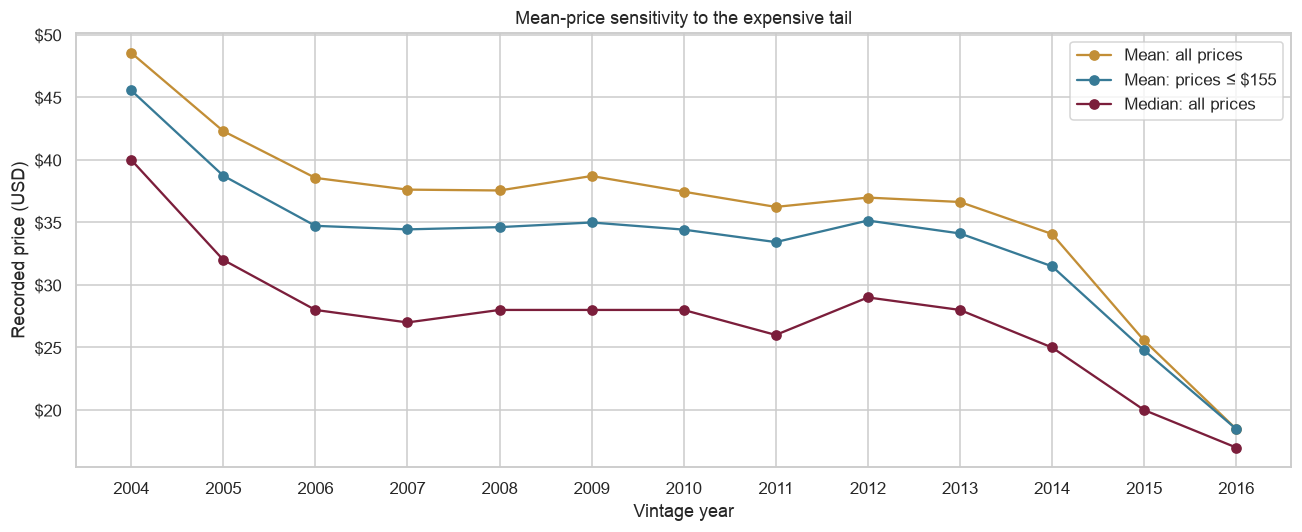

,n_priced,mean_price,median_price,mean_without_top_tail,n_above_cutoff
vintage,,,,,
2004,1546,48.55,40.0,45.55,21
2005,3178,42.30,32.0,38.73,42
2006,4985,38.56,28.0,34.72,76
2007,6198,37.62,27.0,34.44,76
2008,6356,37.55,28.0,34.62,83
2009,8492,38.71,28.0,34.99,108
2010,10291,37.45,28.0,34.42,113
2011,10522,36.24,26.0,33.42,117
2012,13420,36.98,29.0,35.15,120


In [15]:
sensitivity = trend[["n_priced", "mean_price", "median_price"]].copy()
sensitivity["mean_without_top_tail"] = focus.loc[focus["price"].le(cap)].groupby("vintage")["price"].mean()
sensitivity["n_above_cutoff"] = focus.assign(above=focus["price"].gt(cap)).groupby("vintage")["above"].sum()
fig, ax = plt.subplots(figsize=(12, 5))
for column, label, color in [
    ("mean_price", "Mean: all prices", GOLD),
    ("mean_without_top_tail", f"Mean: prices ≤ ${cap:,.0f}", BLUE),
    ("median_price", "Median: all prices", BURGUNDY),
]:
    ax.plot(x, sensitivity[column], marker="o", label=label, color=color)
ax.set(title="Mean-price sensitivity to the expensive tail", xlabel="Vintage year", ylabel="Recorded price (USD)")
ax.set_xticks(x)
ax.yaxis.set_major_formatter(USD)
ax.legend()
plt.tight_layout()
plt.show()
sensitivity.round(2)

In [16]:
focus.nlargest(10, "price")[["title", "vintage", "price", "country", "variety"]]

,title,vintage,price,country,variety
80290,Château les Ormes Sorbet 2013 Médoc,2013,3300.0,France,Bordeaux-style Red Blend
15840,Château Pétrus 2014 Pomerol,2014,2500.0,France,Bordeaux-style Red Blend
98380,Domaine du Comte Liger-Belair 2010 La Romanée,2010,2500.0,France,Pinot Noir
120391,Blair 2013 Roger Rose Vineyard Chardonnay (Arr...,2013,2013.0,US,Chardonnay
65352,Château Pétrus 2011 Pomerol,2011,2000.0,France,Bordeaux-style Red Blend
113564,Domaine du Comte Liger-Belair 2005 La Romanée,2005,2000.0,France,Pinot Noir
1558,Château Margaux 2009 Margaux,2009,1900.0,France,Bordeaux-style Red Blend
111753,Château Lafite Rothschild 2010 Pauillac,2010,1500.0,France,Bordeaux-style Red Blend
111755,Château Cheval Blanc 2010 Saint-Émilion,2010,1500.0,France,Bordeaux-style Red Blend
1575,Château Mouton Rothschild 2009 Pauillac,2009,1300.0,France,Bordeaux-style Red Blend


## 9. Findings from this run
The following summary is computed directly from the focus sample so the values stay consistent when rerun. Endpoint changes describe the reviewed samples; they are not estimates of market-wide inflation or bottle appreciation.

In [17]:
first_year, last_year = focus_years[0], focus_years[-1]
first, last = trend.loc[first_year], trend.loc[last_year]
median_change = 100 * (last["median_price"] / first["median_price"] - 1)
mean_change = 100 * (last["mean_price"] / first["mean_price"] - 1)
print(f"Focus: {first_year}–{last_year}, {len(focus):,} priced reviews.")
print(f"Typical price: median ${focus['price'].median():.2f}; mean ${focus['price'].mean():.2f}.")
print(f"Endpoint median: ${first['median_price']:.2f} → ${last['median_price']:.2f} ({median_change:+.1f}%).")
print(f"Endpoint mean: ${first['mean_price']:.2f} → ${last['mean_price']:.2f} ({mean_change:+.1f}%).")
print(f"Endpoint priced sample sizes: {int(first['n_priced']):,} → {int(last['n_priced']):,}.")
print(f"Smallest / largest focus batches: {int(trend['n_priced'].min()):,} / {int(trend['n_priced'].max()):,}.")
print(f"Missing-price rates across focus years: {trend['missing_price_pct'].min():.1f}%–{trend['missing_price_pct'].max():.1f}%.")
gap = sensitivity["mean_price"] - sensitivity["mean_without_top_tail"]
print(f"Largest reduction in a yearly mean when excluding the top tail: ${gap.max():.2f} ({int(gap.idxmax())}).")

Focus: 2004–2016, 103,824 priced reviews.
Typical price: median $25.00; mean $35.65.
Endpoint median: $40.00 → $17.00 (-57.5%).
Endpoint mean: $48.55 → $18.48 (-61.9%).
Endpoint priced sample sizes: 1,546 → 3,173.
Smallest / largest focus batches: 1,546 / 13,703.
Missing-price rates across focus years: 4.0%–10.4%.
Largest reduction in a yearly mean when excluding the top tail: $3.83 (2006).


**Interpretation and limits**

- Compare medians with means before describing a “typical” wine: a small expensive tail can move the mean substantially.
- Read the coverage and composition plots alongside price trends. Different vintages contain different samples of wines, and the latest vintages may be incomplete.
- These are recorded dollar prices, with no inflation adjustment or observation dates. They do not measure transaction prices, returns to aging, or repeated price changes for the same product.
- Unresolved vintages and missing prices are excluded from price-by-year comparisons. Year extraction is heuristic, so inspect titles if a particular vintage becomes central to the analysis.
- For later modeling, vintages can define chronological batches, as the brief suggests. This notebook supplies descriptive batch summaries; model fitting, temporal evaluation, and review-language analysis remain future work.

**Provenance:** Uses the local Wine Reviews 130k CSV and the project brief’s Team Paso Robles section. Preparation follows the companion notebooks with the documented vintage-parsing adjustment above. This EDA notebook was created with OpenAI Codex assistance.